# 7 · Rewards, discounting and traps

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/MDP_Experiments/blob/main/notebooks/07_rewards_discounting_traps.ipynb)

Scattered through the report are remarks about how the *design* of the two MDPs, their rewards and
their discount factor, shapes the optimal policy:

* two corners of the 39 × 39 world where the policy either waits for ever or postpones a certain
  fall, with the observation that other rewards would make it "commit suicide" instead;
* the suspicion that the elevator's prize of $20N$ "wasn't enough of a reward";
* the aside that "a negative absorbing state for floor 13 would have been interesting".

This notebook follows up on each. The grid-world part comes down to a single inequality. The
elevator part uncovers a structure in the crazy elevator that makes it rather less crazy.

In [ ]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("MDP_Experiments"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/MDP_Experiments"], check=True)
    sys.path.insert(0, os.path.abspath("MDP_Experiments/src"))

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap

import mdplab as ml
from mdplab import plotting as mp
from mdplab import report
from mdplab.gridworld import PIT

mp.use_style()
pd.options.display.float_format = "{:,.3f}".format

## One inequality for both corners

Notebook 2 looked at the two spots of Figure 3 that the report discusses.

* In the **lower left**, two cells are walled in next to a pit. The goal is out of reach. The
  policy pushes against a wall for ever and never enters the pit.
* **Above the lower right**, a cell is surrounded by three pits and the edge of the grid. Every
  move risks a pit, so the fall is certain; the policy picks the move that delays it longest.

Write $c$ for the cost of a move (0.01), $L$ for the penalty of a pit (200) and $\gamma$ for the
discount factor (0.99).

*Waiting for ever* costs $c + \gamma c + \gamma^2 c + \dots = c/(1-\gamma)$. Jumping costs about $L$.
So the agent waits as long as $c/(1-\gamma) < L$.

*Postponing* a certain loss $L$ by one move turns it into $\gamma L$, a gain of $(1-\gamma)L$, at
the price of one more move, $c$. So the agent postpones as long as $c < (1-\gamma)L$.

These are the same condition:

$$\boxed{\,c < (1-\gamma)\,L\,}$$

With the report's numbers the right-hand side is $0.01 \times 200 = 2$, two hundred times the cost
of a move. Both corners are deep inside the region where waiting wins. The smallest world that has
such a corner is one row of four cells: a free cell, a pit, an obstacle and, out of reach behind
it, the goal. Solving it for many combinations of $c$ and $L$ maps the boundary.

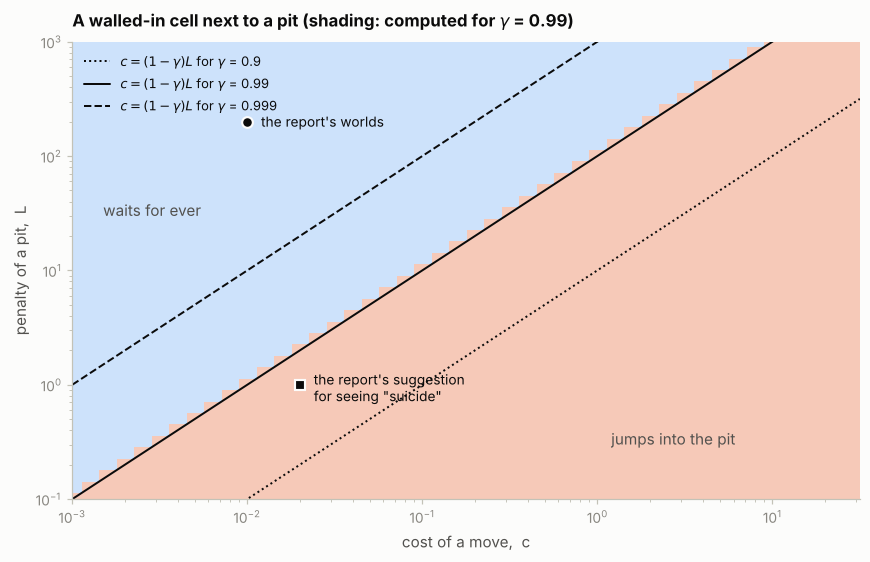

In [2]:
def waits_for_ever(step_cost, pit_penalty, gamma=0.99):
    """Does the optimal policy of the one-cell pocket stay out of the pit?"""
    w = ml.GridWorld.from_text(".x#G", step_reward=-step_cost, pit_reward=-pit_penalty, gamma=gamma)
    policy = ml.policy_iteration(w.mdp).policy
    return ml.hitting_probability(w.mdp, policy, w.mask(PIT))[0] < 0.5


costs = np.logspace(-3, 1.5, 46)
penalties = np.logspace(-1, 3, 41)
region = np.array([[waits_for_ever(c, L) for c in costs] for L in penalties])

fig, ax = plt.subplots(figsize=(7.8, 5))
ax.pcolormesh(costs, penalties, region, cmap=ListedColormap(["#f6c9b8", "#cde2fb"]), shading="nearest")
for gamma, style in ((0.9, (0, (1, 1.6))), (0.99, "-"), (0.999, "--")):
    ax.plot(costs, costs / (1 - gamma), color=mp.INK, linewidth=1.3, linestyle=style, label=rf"$c = (1-\gamma)L$ for $\gamma$ = {gamma}")
ax.plot(0.01, 200, "o", color=mp.INK, markersize=7)
ax.annotate("the report's worlds", (0.01, 200), xytext=(9, 0), textcoords="offset points", va="center", fontsize=9)
ax.plot(0.02, 1, "s", color=mp.INK, markersize=6.5)
ax.annotate('the report\'s suggestion\nfor seeing "suicide"', (0.02, 1), xytext=(9, -2), textcoords="offset points", va="center", fontsize=9)
ax.text(0.0015, 30, "waits for ever", fontsize=10, color=mp.INK_SECONDARY)
ax.text(1.2, 0.3, "jumps into the pit", fontsize=10, color=mp.INK_SECONDARY)
ax.set(xscale="log", yscale="log", xlabel="cost of a move,  c", ylabel="penalty of a pit,  L", ylim=(penalties[0], penalties[-1]), xlim=(costs[0], costs[-1]),
       title=r"A walled-in cell next to a pit (shading: computed for $\gamma$ = 0.99)")
ax.grid(False)
ax.legend(loc="upper left", fontsize=8.5)
mp.savefig(fig, "07_wait_or_jump");

The computed boundary (the edge between the two shaded regions) lies exactly on the line for
γ = 0.99. The report's worlds sit far up in the waiting region. The report also says that "with a
reward (e.g., −1) for the negative absorbing states, and a larger penalty for a 'normal' move
(e.g., −0.02), one begins to observe this suicide option". That point is just across the line, as
the inequality says it should be: $(1-\gamma)L = 0.01 < 0.02$.

The same arithmetic settles the second corner, the cell with three pits around it. The report
found its policy "less than optimal", on the grounds that each bump into the wall adds a cost to
an outcome that cannot be avoided. That reasoning ignores the discount. Postponing is optimal
whenever $c < (1-\gamma)L$, which here means for any discount factor below

In [3]:
gamma_star = 1 - 0.01 / 200
world3 = report.figure3_gridworld()
cell = world3.state(36, 38)
rows_out = []
for gamma in (0.9, 0.99, 0.999, 0.9999, 0.99999):
    wait = -(0.2 * 200 + 0.8 * 0.01) / (1 - 0.8 * gamma)  # bump the edge: 0.8 stay, 0.2 slip into a pit
    rows_out.append({"γ": f"{gamma:g}", "value of bumping the edge and waiting": wait, "value of stepping into the pit on the left": -200.0, "better": "wait" if wait > -200 else "jump"})
display(Markdown(rf"$$\gamma^* = 1 - c/L = {gamma_star:.5f}.$$"))
pd.DataFrame(rows_out).set_index("γ")

$$\gamma^* = 1 - c/L = 0.99995.$$

,value of bumping the edge and waiting,value of stepping into the pit on the left,better
γ,,,
0.9,-142.886,-200.000,wait
0.99,-192.346,-200.000,wait
0.999,-199.243,-200.000,wait
0.9999,-199.960,-200.000,wait
0.99999,-200.032,-200.000,jump


At the report's γ = 0.99 waiting is worth −192.3 and beats the jump by almost 8. The report's
intuition becomes correct only when the future counts for very nearly as much as the present.

## How robust is the scenic route?

The inequality covers cells with no way out. For ordinary cells the question is a different one:
how expensive must a move become before the agent stops taking detours and waiting at walls, and
starts accepting a one-in-ten risk of a pit? The Figure 1 world answers it. Everything is kept as
in the report except the cost of a move, which is varied over five orders of magnitude.

The optimal policy does not change in a single cell until a move costs about **3.2**, three hundred times the report's 0.01. Up to there the agent never enters a pit.

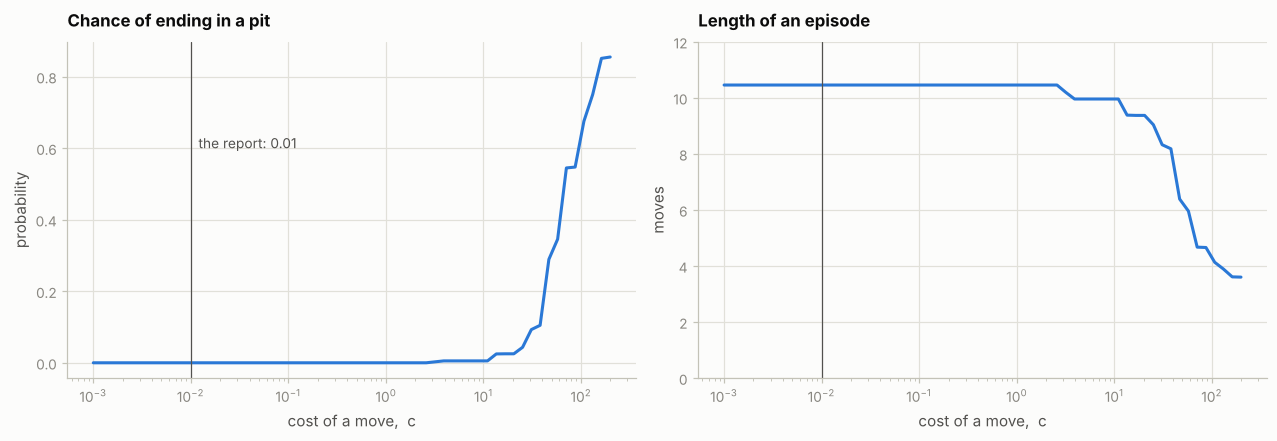

In [4]:
world = ml.GridWorld.report_figure1()
free = world.free
base_policy = ml.policy_iteration(world.mdp).policy
step_costs = np.logspace(-3, 2.3, 60)
rows_out = []
for c in step_costs:
    w = world.replace(step_reward=-c)
    policy = ml.policy_iteration(w.mdp).policy
    out = ml.absorption(w.mdp, policy)
    rows_out.append({
        "cost": c,
        "pit": ml.hitting_probability(w.mdp, policy, w.mask(PIT))[free].mean(),
        "moves": out.steps[free].mean(),
        "changed": int((policy != base_policy)[free].sum()),
    })
sweep = pd.DataFrame(rows_out).set_index("cost")
first_change = sweep.index[(sweep.changed > 0).values.argmax()]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharex=True)
axes[0].plot(sweep.index, sweep.pit, color=mp.SERIES[0])
axes[0].set(xscale="log", xlabel="cost of a move,  c", ylabel="probability", title="Chance of ending in a pit")
axes[1].plot(sweep.index, sweep.moves, color=mp.SERIES[0])
axes[1].set(xlabel="cost of a move,  c", ylabel="moves", title="Length of an episode", ylim=(0, 12))
for ax in axes:
    ax.axvline(0.01, color=mp.INK_SECONDARY, linewidth=0.8)
axes[0].annotate("the report: 0.01", (0.01, 0.6), xytext=(5, 0), textcoords="offset points", fontsize=9, color=mp.INK_SECONDARY)
mp.savefig(fig, "07_step_cost")

display(Markdown(
    f"The optimal policy does not change in a single cell until a move costs about **{first_change:.1f}**, three hundred times the report's 0.01. "
    f"Up to there the agent never enters a pit."
))

The threshold can be worked out by hand for the waiting cells. Waiting at the wall takes ten moves
on average and costs $10c$. Walking past the pit risks a one-in-ten slip that turns +200 into −200,
an expected loss of 40. The two balance near $c = 4$; the exact switch comes a little earlier,
because waiting also delays the +200 and the discount factor charges for that. Beyond that the
policy degrades in stages, and once a
move costs a good fraction of the prize the agent gives up on the goal from more and more cells
and heads for the nearest pit to stop the meter, the grid-wide version of the report's "suicide".

So the scenic routes of Figure 1 are not a fragile feature of one parameter choice. The reward
scheme of the report makes the agent extremely averse to risk, and it would have had to be changed
by orders of magnitude to make it anything else.

## The elevator's prize

In notebook 4 the average reward of the optimal elevator policy rose with the number of floors,
peaked at 34 floors and fell. The report suspected the prize: $20N$ "wasn't enough of a reward".
The cost of a ride grows like $0.27N^2$, so a prize that keeps pace has to grow with $N^2$.

,"presses, prize 20N","presses, prize N²/2",floors with a different button
floors,,,
10,5.221,5.221,0
30,16.401,16.409,1
50,27.779,27.773,1
80,43.922,43.922,0
120,65.276,65.263,19


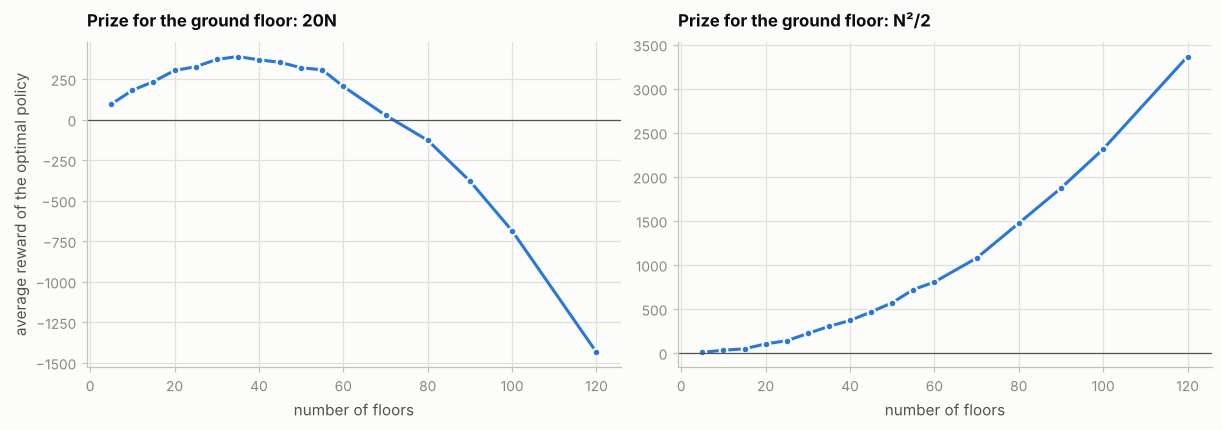

In [5]:
sizes = list(range(5, 61, 5)) + [70, 80, 90, 100, 120]
rows_out = []
for n in sizes:
    row = {"floors": n}
    policies = {}
    for label, prize in (("20N", 20.0 * n), ("N²/2", 0.5 * n * n)):
        m = ml.crazy_elevator(n, goal_reward=prize)
        policies[label] = ml.policy_iteration(m).policy
        out = ml.absorption(m, policies[label])
        row[f"reward, prize {label}"] = out.total_reward[1:].mean()
        row[f"presses, prize {label}"] = out.steps[1:].mean()
    row["floors with a different button"] = int((policies["20N"][1:] != policies["N²/2"][1:]).sum())
    rows_out.append(row)
prize = pd.DataFrame(rows_out).set_index("floors")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, label in zip(axes, ("20N", "N²/2")):
    ax.plot(prize.index, prize[f"reward, prize {label}"], "o-", color=mp.SERIES[0], markersize=5)
    ax.axhline(0, color=mp.INK_SECONDARY, linewidth=0.8)
    ax.set(xlabel="number of floors", title=f"Prize for the ground floor: {label}")
axes[0].set_ylabel("average reward of the optimal policy")
mp.savefig(fig, "07_elevator_prize")
prize[["presses, prize 20N", "presses, prize N²/2", "floors with a different button"]].loc[[10, 30, 50, 80, 120]]

With the report's prize the average reward turns negative between 70 and 80 floors: in a tall
building even the best possible ride loses more on the way than it wins at the bottom. With a
prize of $N^2/2$ it keeps growing.

But the table shows what the prize does *not* change: the policy. The rides are equally long under
both prizes, and where a button differs it is a near-tie that leaves the ride as it was. The
agent was already doing all it could to
reach the ground floor, as notebook 4 found: on nearly every floor the optimal button is the one
with the best direct chance of floor 0. A larger prize makes the same behaviour look better on
paper. In that sense the prize was not too small. There was simply nothing more for it to buy.

## Floor 13, and the families of floors

Why can the elevator's policy do so little? Its formula holds the answer. The destination $j$
enters the transition probability only through one number, $s_j = \sin(j \oplus 2)$:

$$T(k,a,j) \;\propto\; \bigl|\sin\bigl(k + \sin(k\,a + s_j)\bigr)\bigr| .$$

Two floors with similar $s_j$ therefore have similar probabilities under *every* button on *every*
floor. Sorted by $s_j$ instead of by height, the ragged histograms of the report's Figure 5 turn
into smooth curves:

On the right, all 49 floors fall on a single curve: how often a ride passes through a floor is determined by that floor's $s_j$ and by nothing else. Floors near the ground floor's end of the scale are visited about 1.0 times per ride, floor 29, the quietest, 0.16 times.

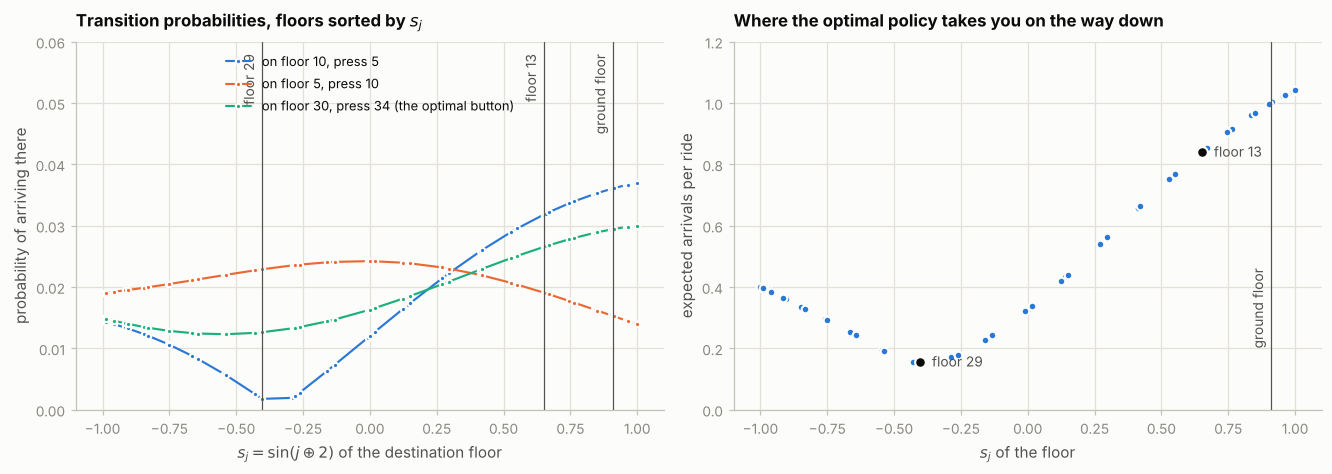

In [6]:
N = 50
T = ml.elevator_transitions(N)
s = np.sin((np.arange(N) ^ 2).astype(float))
order = np.argsort(s)
mdp50 = ml.crazy_elevator(N)
policy50 = ml.policy_iteration(mdp50).policy
P_pi, _ = mdp50.policy_model(policy50)
visits = np.linalg.inv(np.eye(N - 1) - P_pi[1:, 1:])  # expected visits to each floor during a ride
arrivals = (visits - np.eye(N - 1)).mean(axis=0)  # ... not counting the floor the ride starts on
quiet = int(arrivals.argmin()) + 1  # the floor the optimal policy visits least

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for (k, a), colour in zip([(10, 5), (5, 10), (30, int(policy50[30]))], mp.SERIES):
    label = f"on floor {k}, press {a}" + (" (the optimal button)" if k == 30 else "")
    ax.plot(s[order], T[k, a, order], "o-", color=colour, markersize=3.5, linewidth=1.4, label=label)
for floor, name in ((0, "ground floor"), (13, "floor 13"), (quiet, f"floor {quiet}")):
    ax.axvline(s[floor], color=mp.INK_SECONDARY, linewidth=0.8)
    ax.annotate(name, (s[floor], 0.058), xytext=(-3, 0), textcoords="offset points", rotation=90, ha="right", va="top", fontsize=9, color=mp.INK_SECONDARY)
ax.set(xlabel=r"$s_j = \sin(j \oplus 2)$ of the destination floor", ylabel="probability of arriving there", title="Transition probabilities, floors sorted by $s_j$", ylim=(0, 0.06))
ax.legend(loc="upper center", fontsize=8.5)
ax = axes[1]
ax.plot(s[1:], arrivals, "o", color=mp.SERIES[0], markersize=5)
for floor in (13, quiet):
    ax.plot(s[floor], arrivals[floor - 1], "o", color=mp.INK, markersize=7)
    ax.annotate(f"floor {floor}", (s[floor], arrivals[floor - 1]), xytext=(8, -3), textcoords="offset points", fontsize=9, color=mp.INK_SECONDARY)
ax.axvline(s[0], color=mp.INK_SECONDARY, linewidth=0.8)
ax.annotate("ground floor", (s[0], 0.2), xytext=(-3, 0), textcoords="offset points", rotation=90, ha="right", va="bottom", fontsize=9, color=mp.INK_SECONDARY)
ax.set(xlabel=r"$s_j$ of the floor", ylabel="expected arrivals per ride", title="Where the optimal policy takes you on the way down", ylim=(0, 1.2))
mp.savefig(fig, "07_floor_families")

display(Markdown(
    f"On the right, all 49 floors fall on a single curve: how often a ride passes through a floor is determined by that "
    f"floor's $s_j$ and by nothing else. Floors near the ground floor's end of the scale are visited about "
    f"{arrivals.max():.1f} times per ride, floor {quiet}, the quietest, {arrivals.min():.2f} times."
))

A button cannot single out the ground floor. It can only favour a *family* of floors with similar
$s_j$, and the ground floor's family comes along whenever the ground floor is favoured: floors
like 10, 12 and 35 are visited about once per ride. This is why the optimal policy shortens the
ride but cannot steer it towards cheap floors, and why the reward bookkeeping of notebook 4 came
out at half the building's height per press, exactly what random landings would give.

It also answers the report's question about floor 13. Suppose arriving at one floor ends the ride
with a penalty. How well can the policy avoid that floor? It depends on which family the floor
belongs to.

,s of the trap floor,"P(trap), mild penalty (10)","P(trap), penalty 1,000","P(trap), penalty 20,000","ride length, penalty 20,000"
floor 13,0.650,0.443,0.399,0.257,49.464
floor 29,-0.404,0.106,0.093,0.091,25.964
floor 12,0.991,0.510,0.508,0.409,100.336


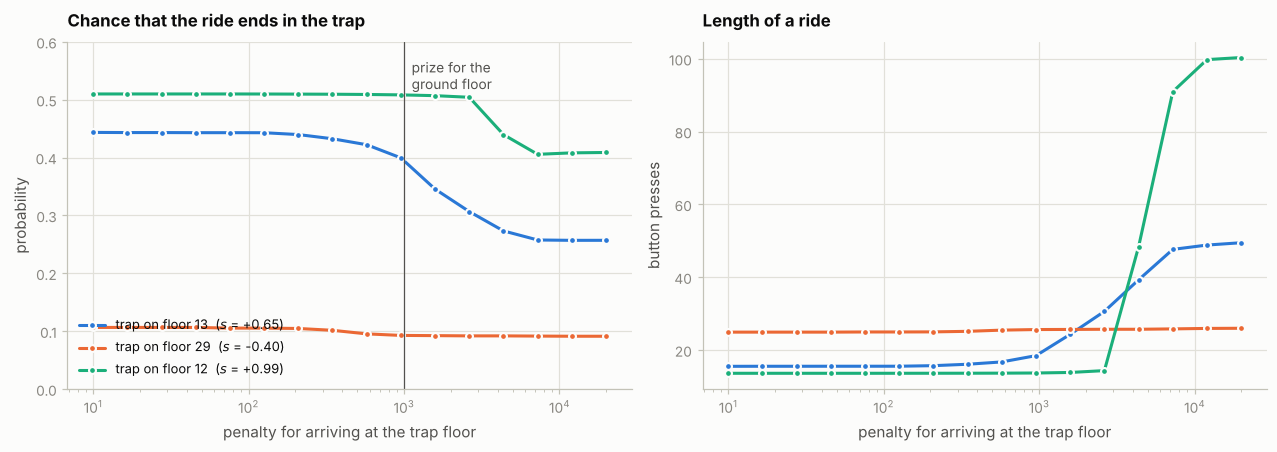

In [7]:
def trap_outcome(trap_floor, penalty):
    m = ml.crazy_elevator(N, trap_floor=trap_floor, trap_reward=-float(penalty))
    policy = ml.policy_iteration(m).policy
    target = np.zeros(N, dtype=bool)
    target[trap_floor] = True
    return ml.hitting_probability(m, policy, target)[m.active].mean(), ml.absorption(m, policy).steps[m.active].mean()


trap_floors = {13: mp.SERIES[0], quiet: mp.SERIES[1], 12: mp.SERIES[2]}
penalty_grid = np.logspace(1, 4.3, 16)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharex=True)
ends = {}
for floor, colour in trap_floors.items():
    results = np.array([trap_outcome(floor, p) for p in penalty_grid])
    ends[floor] = results
    label = f"trap on floor {floor}  ($s$ = {s[floor]:+.2f})"
    axes[0].plot(penalty_grid, results[:, 0], "o-", color=colour, markersize=4.5, label=label)
    axes[1].plot(penalty_grid, results[:, 1], "o-", color=colour, markersize=4.5, label=label)
axes[0].set(xscale="log", xlabel="penalty for arriving at the trap floor", ylabel="probability", title="Chance that the ride ends in the trap", ylim=(0, 0.6))
axes[1].set(xlabel="penalty for arriving at the trap floor", ylabel="button presses", title="Length of a ride")
axes[0].legend(loc="lower left", fontsize=8.5)
axes[0].axvline(1000, color=mp.INK_SECONDARY, linewidth=0.8)
axes[0].annotate("prize for the\nground floor", (1000, 0.57), xytext=(5, 0), textcoords="offset points", va="top", fontsize=9, color=mp.INK_SECONDARY)
mp.savefig(fig, "07_floor13_trap")

summary = pd.DataFrame(
    {
        f"floor {floor}": {
            "s of the trap floor": s[floor],
            "P(trap), mild penalty (10)": ends[floor][0, 0],
            "P(trap), penalty 1,000": ends[floor][np.abs(penalty_grid - 1000).argmin(), 0],
            "P(trap), penalty 20,000": ends[floor][-1, 0],
            "ride length, penalty 20,000": ends[floor][-1, 1],
        }
        for floor in trap_floors
    }
).T
summary

Floor 13 is an awkward floor to fear. Its $s_j$ of 0.65 is close to the ground floor's 0.91, so it
is one of the ground floor's relatives. With a trap there, more than two rides in five end in it,
and raising the penalty helps only slowly: to cut the risk the agent has to shun the whole family,
ground floor included, and the rides get longer and longer. Floor 12, whose $s_j$ is closer still,
is nearly impossible to avoid at all. A trap on the quietest floor, by contrast, catches about one
ride in ten however small the penalty, and the policy hardly has to change to keep it that way.

The report was right that a trap on floor 13 "would have been interesting". It would have shown
that the crazy elevator has a hidden order. Its floors line up along a single coordinate, and a
button is a choice of where along that line to aim.

(This section uses the elevator as it was run, where the coordinate is $\sin(j \oplus 2)$. For the
formula as written the same holds with $\sin(j^2)$; only the membership of the families changes.)

## Summary

| Remark in the report | What the experiments say |
|---|---|
| A walled-in cell bumps for ever instead of entering the pit | Optimal whenever $c < (1-\gamma)L$; with the report's numbers, 0.01 against 2. |
| A doomed cell postpones its fall, which "seems less than optimal" | It is optimal, by the same inequality. The report's intuition holds only for γ above 0.99995. |
| Other rewards would produce "suicide" | Yes, exactly across that line; the report's example (−1, −0.02) is just on the far side. |
| Taking "a scenic route" to avoid pits | Robust: the policy of Figure 1 does not change until a move costs about 3, three hundred times its actual cost. |
| The prize of 20N "wasn't enough" | It makes the average reward negative beyond about 75 floors, but a larger prize does not change the policy. |
| A trap on floor 13 "would have been interesting" | It is hard to avoid, because floor 13 belongs to the ground floor's family. The elevator's floors are ordered by one hidden coordinate. |

Next: [8 · More planners](08_more_planners.ipynb).